In [1]:
import numpy as np
from scipy.optimize import linprog
import matplotlib.pyplot as plt

# --- Dane wejściowe z arkusza Excel ---
# x: Wstępna ocena długości pobytu
# y: Całkowity koszt pobytu
X_data = np.array([120, 144, 48, 168, 24, 96, 192, 72, 48, 120, 216])
Y_data = np.array([2845, 3030, 2568, 3288, 2327, 2966, 3760, 2580, 2772, 3199, 3520])

# Liczba obserwacji
n = len(X_data)
print(f"Krok 1: Przygotowanie danych. Mamy {n} obserwacji (punktów).")

Krok 1: Przygotowanie danych. Mamy 11 obserwacji (punktów).


In [2]:
print("\nKrok 2: Budowa modelu programowania liniowego.")

# --- Wektor współczynników funkcji celu (c) ---
# Nasze zmienne: [a, b, d1+, d1-, d2+, d2-, ..., dn+, dn-]
# Mamy 2 zmienne (a, b) i 2*n zmiennych odchyleń. Łącznie 2 + 2*n zmiennych.
# Chcemy minimalizować sumę wszystkich odchyleń, więc współczynniki dla 'a' i 'b' to 0,
# a dla wszystkich zmiennych d+ i d- to 1.
c = [0, 0] + [1] * (2 * n)
print(f"Model będzie miał {len(c)} zmiennych (2 dla prostej + {2*n} dla odchyleń).")


# --- Macierz ograniczeń równościowych (A_eq) i wektor (b_eq) ---
# Dla każdej obserwacji i tworzymy równanie: a*xi + b - d_plus_i + d_minus_i = yi
A_eq = []
for i in range(n):
    row = [0] * (2 + 2 * n)
    # Współczynnik dla 'a' to xi
    row[0] = X_data[i]
    # Współczynnik dla 'b' to 1
    row[1] = 1
    # Współczynnik dla d_plus_i to -1
    row[2 + 2 * i] = -1
    # Współczynnik dla d_minus_i to 1
    row[2 + 2 * i + 1] = 1
    A_eq.append(row)

# Wektor b_eq to po prostu nasze wartości Y
b_eq = Y_data


# --- Granice dla zmiennych (bounds) ---
# Parametry 'a' i 'b' mogą być dowolne (nieograniczone).
# Zmienne odchyleń muszą być nieujemne (>= 0).
a_bounds = (None, None)
b_bounds = (None, None)
d_bounds = (0, None)

bounds = [a_bounds, b_bounds] + [d_bounds] * (2 * n)


Krok 2: Budowa modelu programowania liniowego.
Model będzie miał 24 zmiennych (2 dla prostej + 22 dla odchyleń).


In [3]:
print("\nKrok 3: Uruchomienie solvera i poszukiwanie optymalnego rozwiązania...")

# Rozwiązanie problemu
result = linprog(c, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method='highs')

if result.success:
    print("\n--- Znaleziono optymalne rozwiązanie! ---")
    
    # Wyodrębnienie wyników
    a_opt = result.x[0]
    b_opt = result.x[1]
    deviations = result.x[2:]
    
    print(f"\nZnalezione parametry funkcji liniowej:")
    print(f"a (nachylenie) = {a_opt:.4f}")
    print(f"b (przecięcie z osią Y) = {b_opt:.4f}")
    print(f"--> Funkcja ma postać: y = {a_opt:.2f} * x + {b_opt:.2f}")
    
    print(f"\nMinimalna suma odchyleń (wartość funkcji celu): {result.fun:.0f}")

    # Wyświetlanie tabeli z wynikami dla każdej obserwacji
    print("\n--- Szczegółowa analiza odchyleń dla każdej obserwacji ---")
    print("{:>5} {:>10} {:>12} {:>14} {:>12} {:>12}".format(
        "Lp.", "X (ocena)", "Y (koszt)", "Prognoza (ax+b)", "Nadwyżka", "Niedomiar"))
    print("-" * 70)
    
    total_y_pred = []
    for i in range(n):
        y_pred = a_opt * X_data[i] + b_opt
        total_y_pred.append(y_pred)
        d_plus = deviations[2 * i]
        d_minus = deviations[2 * i + 1]
        print("{:>5} {:>10} {:>12} {:>14.2f} {:>12.2f} {:>12.2f}".format(
            i+1, X_data[i], Y_data[i], y_pred, d_plus, d_minus))
else:
    print("\nNie udało się znaleźć optymalnego rozwiązania.")
    print(f"Status: {result.message}")



Krok 3: Uruchomienie solvera i poszukiwanie optymalnego rozwiązania...

--- Znaleziono optymalne rozwiązanie! ---

Znalezione parametry funkcji liniowej:
a (nachylenie) = 6.0000
b (przecięcie z osią Y) = 2280.0000
--> Funkcja ma postać: y = 6.00 * x + 2280.00

Minimalna suma odchyleń (wartość funkcji celu): 1395

--- Szczegółowa analiza odchyleń dla każdej obserwacji ---
  Lp.  X (ocena)    Y (koszt) Prognoza (ax+b)     Nadwyżka    Niedomiar
----------------------------------------------------------------------
    1        120         2845        3000.00       155.00         0.00
    2        144         3030        3144.00       114.00         0.00
    3         48         2568        2568.00         0.00         0.00
    4        168         3288        3288.00         0.00         0.00
    5         24         2327        2424.00        97.00         0.00
    6         96         2966        2856.00         0.00       110.00
    7        192         3760        3432.00         0.0

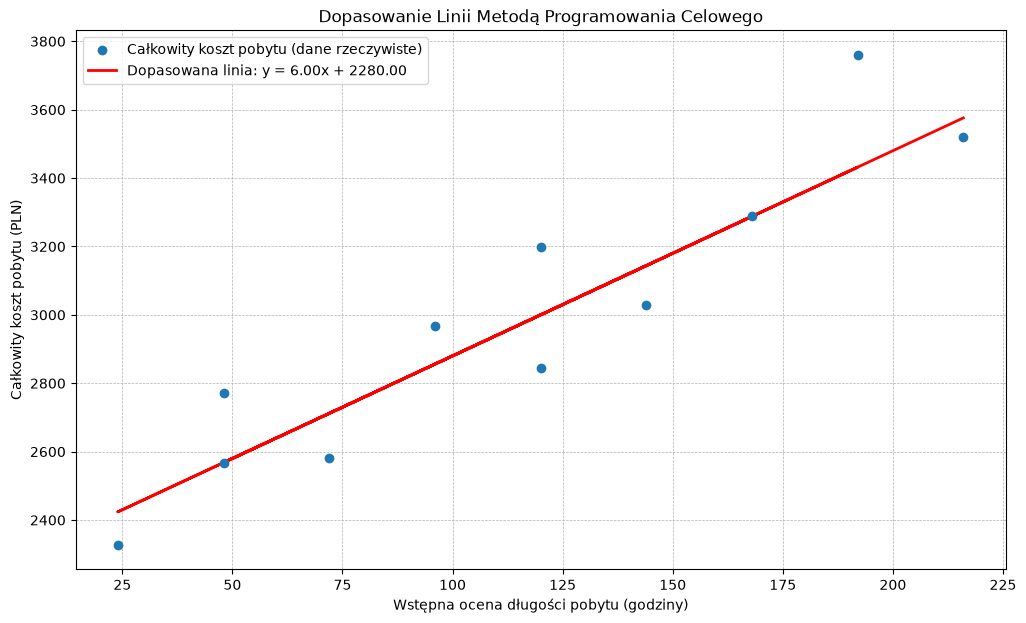

In [4]:
# Wizualizacja wyników
plt.figure(figsize=(12, 7))
# Punkty danych
plt.scatter(X_data, Y_data, label='Całkowity koszt pobytu (dane rzeczywiste)', color='C0', zorder=5)
# Linia regresji znalezionej przez programowanie celowe
plt.plot(X_data, total_y_pred, label=f'Dopasowana linia: y = {a_opt:.2f}x + {b_opt:.2f}', color='red', linewidth=2)

plt.title('Dopasowanie Linii Metodą Programowania Celowego')
plt.xlabel('Wstępna ocena długości pobytu (godziny)')
plt.ylabel('Całkowity koszt pobytu (PLN)')
plt.legend()
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.show()